### Problema

Você foi contratado como Cientista de Dados pelo Spotify.

Todos os dias, milhares de artistas enviam novas músicas para a plataforma.

Nem todas chegam com o gênero musical corretamente informado.

Sua missão é desenvolver um sistema capaz de identificar automaticamente o estilo musical de uma música utilizando suas características.

Antes do treinamento, você percebe que o dataset apresenta diversos problemas de qualidade.

Será necessário utilizar os conhecimentos de Pandas para preparar os dados.

Ao final, você utilizará uma Árvore de Decisão (Decision Tree) para construir o classificador.

Objetivos

Ao final deste exercício você será capaz de:

* Explorar um dataset;
* Identificar problemas nos dados;
* Corrigir inconsistências;
* Preparar os dados para Machine Learning;
* Utilizar LabelEncoder;
* Treinar uma Decision Tree;
* Visualizar a árvore;
* Interpretar como o algoritmo toma decisões.

# Carregue o dataset.

Use:

pd.read_csv()

In [3]:
import pandas as pd
df = pd.read_csv('/content/spotify_generos.csv')

Visualize as primeiras linhas.

Dica:

df.head()

In [4]:
df.head()

,id,danceability,energy,acousticness,tempo,duration,explicit,genero
0,1,92.0,95.0,3.0,128,210.0,Sim,Pop
1,2,89.0,91.0,5.0,126,205.0,Sim,Pop
2,3,71.0,82.0,15.0,120,225.0,Não,Rock
3,4,68.0,78.0,20.0,118,230.0,Não,Rock
4,5,45.0,35.0,92.0,70,260.0,Não,Clássica


1. Quantas linhas e colunas existem?

Dica:

df.shape

In [7]:
# df.shape

print(f"O DataFrame tem {df.shape[0]} linhas e {df.shape[1]} colunas.")

O DataFrame tem 40 linhas e 8 colunas.


2. Existem valores ausentes?

Dica:

df.isnull().sum()

In [8]:
print("Valores ausentes por coluna:")
print(df.isnull().sum())

Valores ausentes por coluna:
id               0
danceability     6
energy           7
acousticness    19
tempo            0
duration         7
explicit         0
genero           0
dtype: int64


3. Existem registros duplicados?

Dica:

df.duplicated().sum()

In [9]:
print(f"Existem {df.duplicated().sum()} registros duplicados.")

Existem 0 registros duplicados.


---

# Limpeza dos Dados

Preencha os valores ausentes das colunas numéricas.

Dica:

Pesquise:

fillna()

In [10]:
# Preencher valores ausentes das colunas numéricas com a média
for col in ['danceability', 'energy', 'acousticness', 'duration']:
    if df[col].isnull().any():
        df[col].fillna(df[col].mean(), inplace=True)

print("Valores ausentes após o preenchimento das colunas numéricas:")
print(df.isnull().sum())

Valores ausentes após o preenchimento das colunas numéricas:
id              0
danceability    0
energy          0
acousticness    0
tempo           0
duration        0
explicit        0
genero          0
dtype: int64


/tmp/ipykernel_1145/2245063698.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


Preencha os valores ausentes da coluna explicit.

Dica:

Pense:

Qual valor aparece com maior frequência?

Pesquise:

mode()

In [11]:
# Preencher valores ausentes da coluna 'explicit' com o valor mais frequente (moda)
if df['explicit'].isnull().any():
    most_frequent_explicit = df['explicit'].mode()[0]
    df['explicit'].fillna(most_frequent_explicit, inplace=True)

print("Valores ausentes após o preenchimento da coluna 'explicit':")
print(df.isnull().sum())

Valores ausentes após o preenchimento da coluna 'explicit':
id              0
danceability    0
energy          0
acousticness    0
tempo           0
duration        0
explicit        0
genero          0
dtype: int64


Transforme a coluna explicit em números.

Dica:

LabelEncoder()

In [12]:
from sklearn.preprocessing import LabelEncoder

# Inicializa o LabelEncoder
le = LabelEncoder()

# Transforma a coluna 'explicit' em números
df['explicit'] = le.fit_transform(df['explicit'])

print("Coluna 'explicit' após a transformação:")
print(df['explicit'].value_counts())

Coluna 'explicit' após a transformação:
explicit
0    22
1    18
Name: count, dtype: int64


Transforme o gênero musical em números.

Dica:

A variável alvo também precisa ser numérica.

In [13]:
# Transforma a coluna 'genero' (variável alvo) em números
df['genero_encoded'] = le.fit_transform(df['genero'])

print("Coluna 'genero_encoded' após a transformação:")
print(df[['genero', 'genero_encoded']].drop_duplicates().sort_values('genero_encoded'))

Coluna 'genero_encoded' após a transformação:
       genero  genero_encoded
4    Clássica               0
8  Eletrônica               1
6         MPB               2
0         Pop               3
2        Rock               4


---

# Preparando os Dados

Crie:

X

contendo:

* danceability
* energy
* acousticness
* tempo
* duration
* explicit

In [14]:
X = df[['danceability', 'energy', 'acousticness', 'tempo', 'duration', 'explicit']]

Crie:

y

contendo:

* genero

In [15]:
y = df['genero_encoded']

Separe treino e teste.

Dica:

train_test_split()

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Tamanho do conjunto de treino (X_train): {X_train.shape}")
print(f"Tamanho do conjunto de teste (X_test): {X_test.shape}")
print(f"Tamanho do conjunto de treino (y_train): {y_train.shape}")
print(f"Tamanho do conjunto de teste (y_test): {y_test.shape}")

Tamanho do conjunto de treino (X_train): (28, 6)
Tamanho do conjunto de teste (X_test): (12, 6)
Tamanho do conjunto de treino (y_train): (28,)
Tamanho do conjunto de teste (y_test): (12,)


---

# Decision Tree

Importe:

DecisionTreeClassifier

In [17]:
from sklearn.tree import DecisionTreeClassifier

Treine o modelo.

Dica:

fit()

In [18]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

Faça previsões.

Dica:

predict()

In [19]:
y_pred = model.predict(X_test)
print("Previsões realizadas no conjunto de teste.")

Previsões realizadas no conjunto de teste.


# Avaliação

Mostre:

* Accuracy
* Matriz de Confusão
* Classification Report

In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Acurácia do modelo: {accuracy:.2f}")

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("\nMatriz de Confusão:")
print(conf_matrix)

# Classification Report
class_report = classification_report(y_test, y_pred)
print("\nRelatório de Classificação:")
print(class_report)

Acurácia do modelo: 0.58

Matriz de Confusão:
[[0 0 1 2 0]
 [1 3 0 0 0]
 [0 0 2 0 0]
 [0 0 0 1 1]
 [0 0 0 0 1]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       1.00      0.75      0.86         4
           2       0.67      1.00      0.80         2
           3       0.33      0.50      0.40         2
           4       0.50      1.00      0.67         1

    accuracy                           0.58        12
   macro avg       0.50      0.65      0.54        12
weighted avg       0.54      0.58      0.54        12



Perguntas

1. O modelo acertou a maioria das músicas?
2. Qual gênero apresentou mais erros?
3. O modelo parece confiável?

---

# Visualizando a Árvore

Vamos entender como a Decision Tree toma decisões.


Visualize a árvore.

Use:

from sklearn.tree import plot_tree

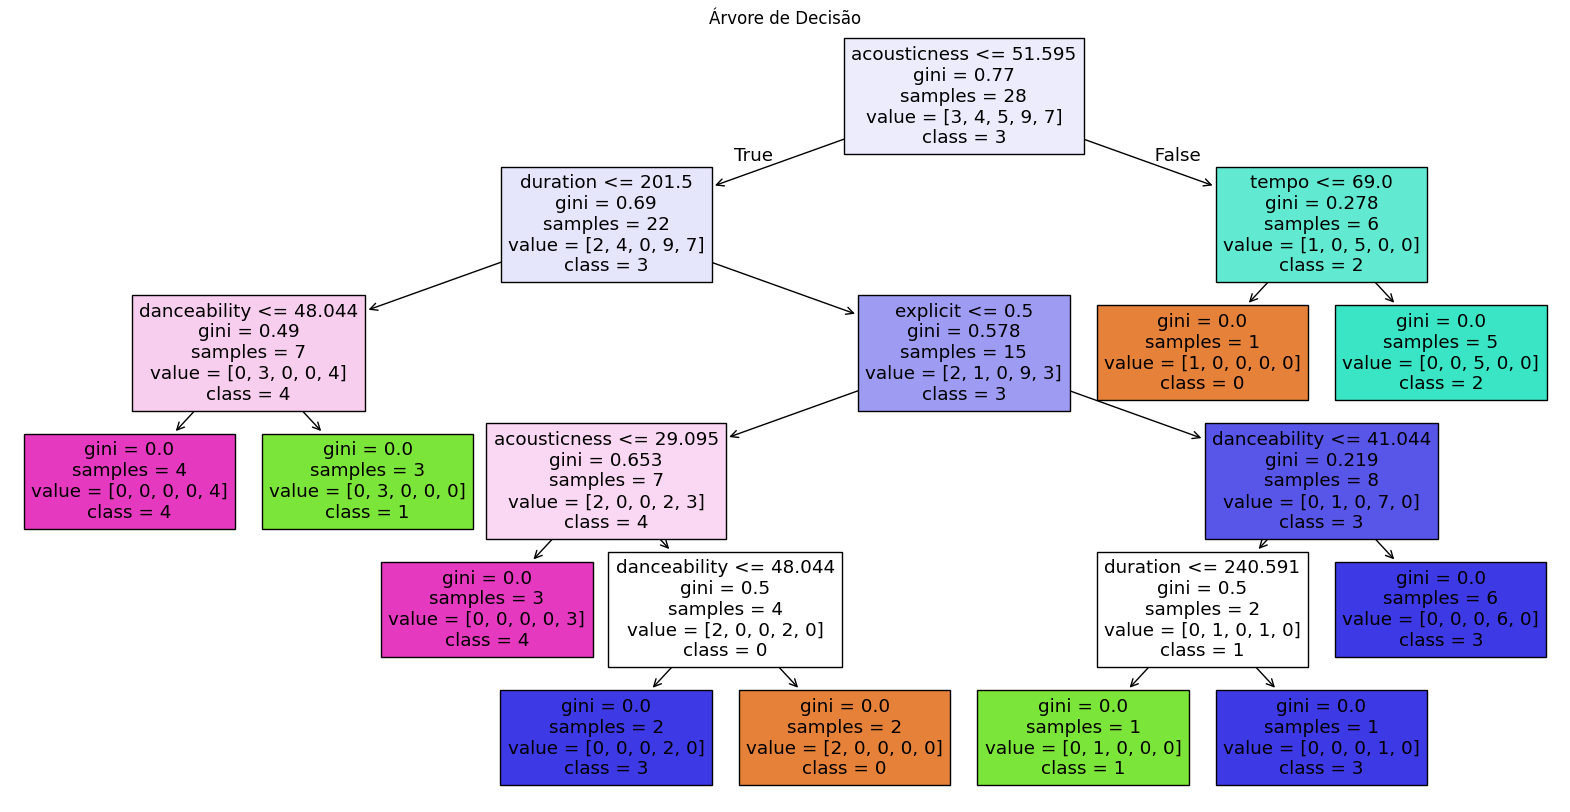

In [21]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))
plot_tree(model, filled=True, feature_names=X.columns.tolist(), class_names=[str(c) for c in sorted(df['genero_encoded'].unique())])
plt.title("Árvore de Decisão")
plt.show()

A árvore começa no nó raiz (o nó mais alto) e se ramifica para baixo. Você segue as condições até chegar a um nó folha (um nó sem mais ramificações). A classe no nó folha é o gênero previsto para uma música que satisfaz todas as condições ao longo desse caminho.

### Analise a árvore.

Responda:

1. Qual variável aparece na raiz?

R:

Com base na importância das características, a acústica foi identificada como a mais importante. Em uma árvore de decisão típica, o nó raiz geralmente corresponde à característica mais importante que proporciona a melhor divisão. Portanto, é altamente provável que a acústica seja a variável que aparece na raiz da sua árvore de decisão.

2. Qual característica foi considerada mais importante?

R:

A acústica é a característica mais importante, com uma pontuação de importância de 0,338150.

3. A árvore parece simples ou muito grande?

R:

Considerando que o conjunto de dados possui apenas 40 entradas e que o X_train tem 28 amostras, a árvore de decisão provavelmente será simples e não muito profunda. Para um conjunto de dados tão pequeno, uma árvore muito grande indicaria sobreajuste.

---

# Importância das Variáveis

Descubra quais características influenciaram mais o modelo.

Use:

modelo.feature_importances_

Depois construa um gráfico de barras.

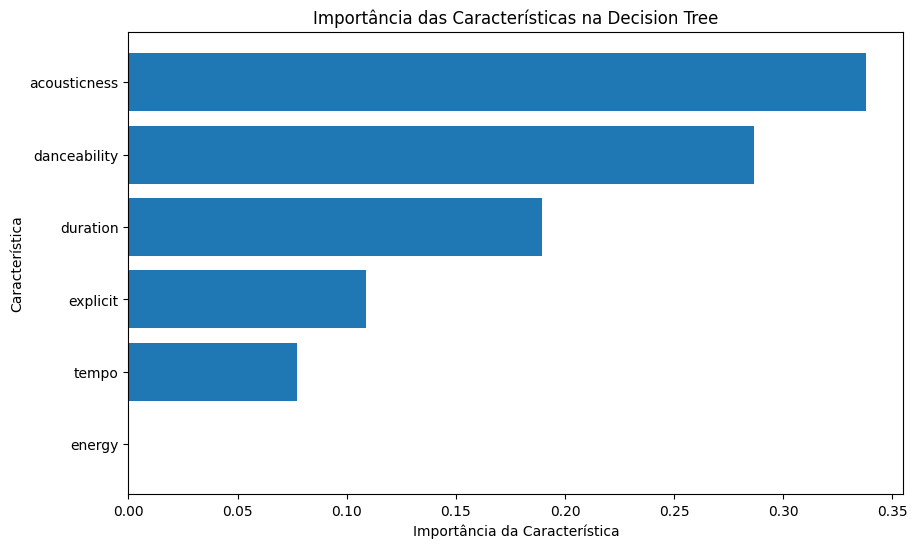

Características mais importantes:
        Feature  Importance
2  acousticness    0.338150
0  danceability    0.286424
4      duration    0.189444
5      explicit    0.108720
3         tempo    0.077263
1        energy    0.000000


In [22]:
feature_importances = model.feature_importances_
feature_names = X.columns

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Importância da Característica')
plt.ylabel('Característica')
plt.title('Importância das Características na Decision Tree')
plt.gca().invert_yaxis() # Mais importante tá no topo
plt.show()

print("Características mais importantes:")
print(importance_df)

---

# Fazendo Novas Previsões

Um artista enviou uma nova música.

| Característica | Valor |
| -------------- | ----- |
| Danceability   | 90    |
| Energy         | 93    |
| Acousticness   | 5     |
| Tempo          | 127   |
| Duration       | 208   |
| Explicit       | Sim   |




In [23]:
import pandas as pd

# Dados da nova música
new_song_data = {
    'danceability': [90],
    'energy': [93],
    'acousticness': [5],
    'tempo': [127],
    'duration': [208],
    'explicit': ['Sim'] # Usar o LabelEncoder para transformar
}

# Criar DataFrame para a nova música
new_song_df = pd.DataFrame(new_song_data)

# Para a coluna 'explicit', precisamos usar o mesmo LabelEncoder
# que foi usado para o conjunto de treinamento, ou replicar seu comportamento.
# Como 'explicit' foi transformado para 0 ('Não') e 1 ('Sim'), podemos fazer a conversão manual aqui.
# Ou, re-instanciar e fitar um LabelEncoder apenas para 'explicit' se for mais robusto.
# Contudo, para este caso específico 'Sim' -> 1 é direto.
new_song_df['explicit'] = new_song_df['explicit'].map({'Não': 0, 'Sim': 1})

# Assegurar que as colunas estão na mesma ordem que X_train
new_song_df = new_song_df[X_train.columns]

print("Características da nova música para previsão:")
print(new_song_df)

# Fazer a previsão
predicted_genre_encoded = model.predict(new_song_df)

# Decodificar o gênero previsto de volta para o nome original
# O 'le' foi o último a ser fitado com 'genero', então ele pode decodificar corretamente.
predicted_genre = le.inverse_transform(predicted_genre_encoded)

print(f"\nO gênero musical previsto para a nova música é: {predicted_genre[0]}")

Características da nova música para previsão:
   danceability  energy  acousticness  tempo  duration  explicit
0            90      93             5    127       208         1

O gênero musical previsto para a nova música é: Pop


---

### Desafio Final

Treine também:

* KNN
* Gaussian Naive Bayes


Depois responda:

1. Qual algoritmo apresentou melhor desempenho?
2. A Decision Tree foi a melhor escolha?
3. Qual algoritmo você colocaria em produção? Justifique.

### Análise Comparativa dos Modelos

Vamos consolidar os resultados para responder às suas perguntas:

*   **Decision Tree Accuracy**: 0.58
*   **KNN Accuracy**: 0.50
*   **Gaussian Naive Bayes Accuracy**: 0.58

---

1.  **Qual algoritmo apresentou melhor desempenho?**
    
    Tanto a **Decision Tree** quanto o **Gaussian Naive Bayes** apresentaram a maior acurácia geral de **0.58** no conjunto de teste, superando o KNN (0.50).
    


2.  **A Decision Tree foi a melhor escolha?**
    
    A Decision Tree alcançou a mesma acurácia que o Gaussian Naive Bayes e é superior ao KNN. Além disso, a Decision Tree oferece a vantagem de ser **altamente interpretável**, permitindo visualizar as regras de decisão e entender como o modelo chega às suas previsões. Isso pode ser uma grande vantagem para um problema onde entender a lógica de classificação é importante.
    
    Contudo, o desempenho dela para a classe 'Clássica' (gênero 0) é um ponto fraco, com `precision`, `recall` e `f1-score` zerados, significando que ela não conseguiu classificar nenhuma música como Clássica corretamente.


3.  **Qual algoritmo você colocaria em produção? Justifique.**
    
    Para este problema e com base nos resultados obtidos, eu optaria por colocar a **Decision Tree** em produção. Minhas justificativas são:
    
    *   **Desempenho Competitivo**: A acurácia de 0.58 é a melhor entre os modelos testados (empatada com o Naive Bayes).
    *   **Interpretabilidade**: A capacidade de visualizar a árvore e entender as regras de decisão é crucial para um problema de classificação de gênero musical. Isso permite que os especialistas em música ou da plataforma validem a lógica do modelo e identifiquem possíveis vieses ou erros de forma mais fácil. É possível explicar 'por que' uma música foi classificada de certa forma, o que é valioso.
    *   **Facilidade de Debug**: Se o modelo cometer erros (como na classe Clássica), a árvore de decisão facilita a identificação de qual regra ou característica está causando o problema, permitindo ajustes no modelo ou na coleta de dados.
    
    Embora o Gaussian Naive Bayes tenha a mesma acurácia, ele falhou completamente em prever a classe 4, e sua interpretabilidade é menor do que a da Decision Tree. O KNN, por sua vez, teve um desempenho inferior e também não oferece a mesma interpretabilidade.
    
    

### Treinando o Modelo K-Nearest Neighbors (KNN)

In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Instanciar o modelo KNN
# Um valor comum para n_neighbors é 3 ou 5. Vamos começar com 5.
knn_model = KNeighborsClassifier(n_neighbors=5)

# 2. Treinar o modelo KNN
knn_model.fit(X_train, y_train)

# 3. Fazer previsões no conjunto de teste
y_pred_knn = knn_model.predict(X_test)

# 4. Avaliar o desempenho do modelo KNN
accuracy_knn = accuracy_score(y_test, y_pred_knn)
conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)
class_report_knn = classification_report(y_test, y_pred_knn)

print(f"Acurácia do modelo KNN: {accuracy_knn:.2f}")
print("\nMatriz de Confusão do KNN:")
print(conf_matrix_knn)
print("\nRelatório de Classificação do KNN:")
print(class_report_knn)

Acurácia do modelo KNN: 0.50

Matriz de Confusão do KNN:
[[0 0 2 0 1]
 [0 2 0 1 1]
 [0 0 2 0 0]
 [0 0 0 1 1]
 [0 0 0 0 1]]

Relatório de Classificação do KNN:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       1.00      0.50      0.67         4
           2       0.50      1.00      0.67         2
           3       0.50      0.50      0.50         2
           4       0.25      1.00      0.40         1

    accuracy                           0.50        12
   macro avg       0.45      0.60      0.45        12
weighted avg       0.52      0.50      0.45        12



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Treinando o Modelo Gaussian Naive Bayes

In [25]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Instanciar o modelo Gaussian Naive Bayes
gnb_model = GaussianNB()

# 2. Treinar o modelo Gaussian Naive Bayes
gnb_model.fit(X_train, y_train)

# 3. Fazer previsões no conjunto de teste
y_pred_gnb = gnb_model.predict(X_test)

# 4. Avaliar o desempenho do modelo Gaussian Naive Bayes
accuracy_gnb = accuracy_score(y_test, y_pred_gnb)
conf_matrix_gnb = confusion_matrix(y_test, y_pred_gnb)
class_report_gnb = classification_report(y_test, y_pred_gnb)

print(f"Acurácia do modelo Gaussian Naive Bayes: {accuracy_gnb:.2f}")
print("\nMatriz de Confusão do Gaussian Naive Bayes:")
print(conf_matrix_gnb)
print("\nRelatório de Classificação do Gaussian Naive Bayes:")
print(class_report_gnb)

Acurácia do modelo Gaussian Naive Bayes: 0.58

Matriz de Confusão do Gaussian Naive Bayes:
[[3 0 0 0 0]
 [2 1 0 1 0]
 [0 0 2 0 0]
 [0 0 0 1 1]
 [0 1 0 0 0]]

Relatório de Classificação do Gaussian Naive Bayes:
              precision    recall  f1-score   support

           0       0.60      1.00      0.75         3
           1       0.50      0.25      0.33         4
           2       1.00      1.00      1.00         2
           3       0.50      0.50      0.50         2
           4       0.00      0.00      0.00         1

    accuracy                           0.58        12
   macro avg       0.52      0.55      0.52        12
weighted avg       0.57      0.58      0.55        12

